In [1]:
using Revise
using LinearAlgebra
using NLsolve
using Plots
using LaTeXStrings

gr();
# pyplot();
# plotlyjs();

In [2]:
BLAS.set_num_threads(1)

In [3]:
using GaussianSpectralDensities

# Dynamics of a random neural network with one planted memory

$$
\newcommand{\bm}[1]{\boldsymbol{#1}}
$$

$$
\begin{aligned}
\frac{d x_i}{dt} &= -x_i + \sum_{j = 1}^N \tilde{J}_{ij} \tanh x_j \ , \\
\tilde{J} &= \frac{\hat{\bm{x}} \tanh \hat{\bm{x}}}{\|\tanh \hat{\bm{x}}\|^2} + \sigma J \, , \\
\langle J_{ij} J_{kl} \rangle &= \frac{1}{N} \left(\delta_{ik} \delta_{jl} + \tau \delta_{il} \delta_{kj} \right) \, .
\end{aligned}
$$

The memory $\hat{\bm{x}}$ is a randomly sampled vector, and the model
is set up such that, in the absence of coupling noise ($\sigma = 0$),
there is a fixed point at $\bm{x} = \hat{\bm{x}}$. What happens as
noise is turned on, and what is the effect of symmetry $\tau$?

Note that the $\tanh$ breaks rotational symmetry, so different
$\hat{\bm{x}}$ with the same norm do not necessarily give equivalent
dynamics. Should this inform our choice of measure for sampling
memories? No, I think sampling something like a Gaussian $\hat{\bm{x}}$
is the most sensible approach. It maintains permutation invariance
but not full rotational invariance, which actually seems desirable in
a nonlinear model.

Let's run some simulations.

In [4]:
function network_f!(dx, x, J̃, t)
    mul!(dx, J̃, tanh.(x))
    dx .-= x
end

function network_jac!(jac, x, J̃, t)
    for j in 1:length(x)
        for i in 1:length(x)
            jac[i, j] = J̃[i, j] / (cosh(x[j])^2)
        end
        jac[j, j] -= one(eltype(jac))
    end
end

function poor_mans_network_jac!(jac, x, J̃, t, dx)
    xx = copy(x)
    fx = similar(xx)
    fxdx = similar(xx)
    network_f!(fx, xx, J̃, t)
    for j in 1:N
        xx[j] += dx
        network_f!(fxdx, xx, J̃, t) 
        jac[:, j] = (fxdx - fx) / (xx[j] - x[j])
        xx[j] = x[j]
    end
end

poor_mans_network_jac! (generic function with 1 method)

In [5]:
ftype = Float64

N = 256
s = one(ftype)
x̂ = s * randn(ftype, N)
tx̂ = tanh.(x̂)
Ĵ = x̂ * tx̂' / dot(tx̂, tx̂)
Ĵ[diagind(Ĵ)] .= zero(ftype);

In [6]:
σ = ftype(0.4)
τ = ftype(0.5)

J = randn(ftype, N, N) / ftype(sqrt(N))
J = partially_hermitize(J, τ)
J[diagind(J)] .= zero(ftype)

J̃ = Ĵ + σ * J;

In [7]:
# Verify Jacobian
jaca = similar(J̃)
jacb = similar(J̃)
network_jac!(jaca, x̂, J̃, zero(ftype))
poor_mans_network_jac!(jacb, x̂, J̃, zero(ftype), sqrt(eps(ftype)))
opnorm(jacb - jaca)

7.223849255082757e-7

In [8]:
sol = nlsolve(
    (dx, x) -> network_f!(dx, x, J̃, zero(ftype)),
    (jac, x) -> network_jac!(jac, x, J̃, zero(ftype)),
    x̂;
    method=:newton,
    ftol=sqrt(eps(ftype)),
)
if !converged(sol)
    error("failed to converge")
end
x₀ = sol.zero
jac = similar(J̃)
network_jac!(jac, x₀, J̃, zero(ftype))
jacevs = eigvals(jac)
println(maximum(real(jacevs)))

-0.5450697371256208


In [9]:
import LazySets

R = Diagonal(cosh.(x₀).^(-2))
ensemble = MatrixEnsemble(Ĵ * R - I, σ * I, R, τ)

Mevs = unique(eigvals(ensemble.M))
A, _J = sample(ftype, ensemble)
Aevs = eigvals(A)

region = spectral_region(Aevs)
xs, ys, zs = autogrid(region);

In [10]:
i, j = 15, 80
za = zs[i, j - 1]
zb = zs[i - 1, j]
zc = zs[i, j];

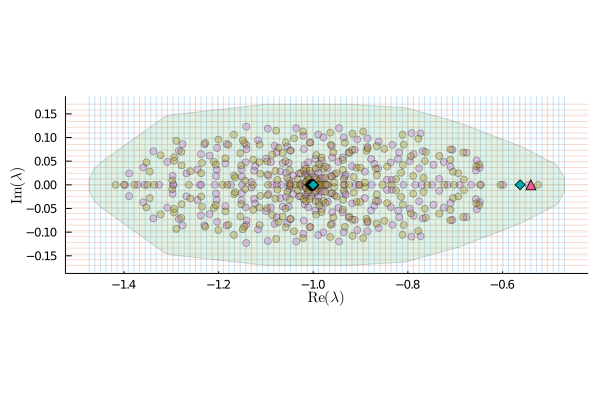

In [11]:
p = vline(xs, label="", alpha=0.25, xlims=(xs[1], xs[end]))
hline!(p, ys, label="", alpha=0.25, ylims=(ys[1], ys[end]))
plot!(
    p,
    region,
    alpha=0.15,
    aspect_ratio=:equal,
    xlabel=L"\mathrm{Re}(\lambda)",
    ylabel=L"\mathrm{Im}(\lambda)",
    tickfontsize=8,
    guidefontsize=10,
)

scatter!(p, real(jacevs), imag(jacevs), alpha=1.0 / 3.0, label="")
scatter!(p, real(Aevs), imag(Aevs), alpha=1.0 / 3.0, label="")
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markersize=5, label="")

scatter!(p, xs[[j]], ys[[i]], markershape=:utriangle, markersize=5, label="")

In [12]:
objective = Fixk();
algorithm = Rampδ²();

In [13]:
verbosity = 3;

solver = SpectralSolver(ensemble, objective, algorithm);
solutiona = solve!(solver, za; verbosity=verbosity, store_trace=true);
solutionb = solve!(solver, zb; verbosity=verbosity, store_trace=true);
qa, δa² = solutiona.q, solutiona.δ²;
qb, δb² = solutionb.q, solutionb.δ²;
qc, δc² = GaussianSpectralDensities.select(qa, qb, δa², δb²);
GaussianSpectralDensities.print_q(qc);
GaussianSpectralDensities.print_δ²(δc²);
solutionc = solve!(
    solver, zc,
    qc, δc²;
    verbosity=verbosity, store_trace=true,
);
solver = nothing;  # Hand workspace over to GC

 z = -0.552 + i 0.000
-------------------------------------------------------------------
    μ       γ²         δ²                  q                k
-------  ----------  ---------  ------------------------  ---------
  1.000   2.560e+02  2.560e+02   7.377e-03 + i 0.000e+00  3.519e-03
  1.000   1.280e+02  1.280e+02   1.270e-02 + i 0.000e+00  6.769e-03
  1.000   6.400e+01  6.400e+01   2.161e-02 + i 0.000e+00  1.285e-02
  1.000   3.200e+01  3.200e+01   3.620e-02 + i 0.000e+00  2.389e-02
  1.000   1.600e+01  1.600e+01   5.916e-02 + i 0.000e+00  4.317e-02
  1.000   8.000e+00  8.000e+00   9.315e-02 + i 0.000e+00  7.488e-02
  1.000   3.998e+00  4.000e+00   1.395e-01 + i 0.000e+00  1.232e-01
  1.000   1.992e+00  2.000e+00   1.969e-01 + i 0.000e+00  1.907e-01
  1.000   9.825e-01  1.000e+00   2.611e-01 + i 0.000e+00  2.766e-01
  1.000   4.684e-01  5.000e-01   3.263e-01 + i 0.000e+00  3.769e-01
  1.000   2.014e-01  2.500e-01   3.874e-01 + i 0.000e+00  4.867e-01
  1.000   5.889e-02  1.250e-01  

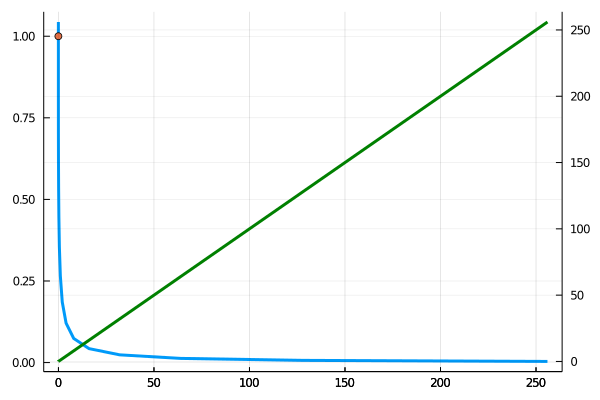

In [14]:
sol = solutionb

plot(sol.trace.γ², sol.trace.k, lw=3, label="")
scatter!([sol.γ²], [sol.k], label="")
plot!(twinx(), sol.trace.γ², sol.trace.δ², lw=3, color=:green, label="")

In [15]:
problem = SpectralProblem(ensemble, objective, zs);
solution = solve(problem, algorithm; chunks_per_thread=1);

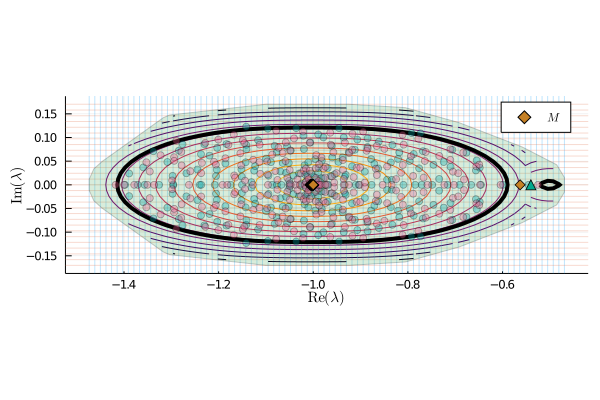

In [16]:
p = vline(xs, label="", xlims=(xs[1], xs[end]), alpha=0.25)
hline!(p, ys, label="", ylims=(ys[1], ys[end]), alpha=0.25)
plot!(
    p,
    region,
    alpha=0.2,
    aspect_ratio=:equal,
    xlabel=L"\mathrm{Re}(\lambda)",
    ylabel=L"\mathrm{Im}(\lambda)",
    tickfontsize=8,
    guidefontsize=10,
)

contour!(p, xs, ys, solution.γ², colorbar=false)
contour!(p, xs, ys, solution.γ², levels=[0.0], color=:black, linewidth=4)

scatter!(p, real(jacevs), imag(jacevs), alpha=1.0 / 3.0, label="")
scatter!(p, real(Aevs), imag(Aevs), alpha=1.0 / 3.0, label="")
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markersize=5, label=L"M")

scatter!(p, xs[[j]], ys[[i]], markershape=:utriangle, markersize=5, label="")

vline!([0.0], color=:black, label="")

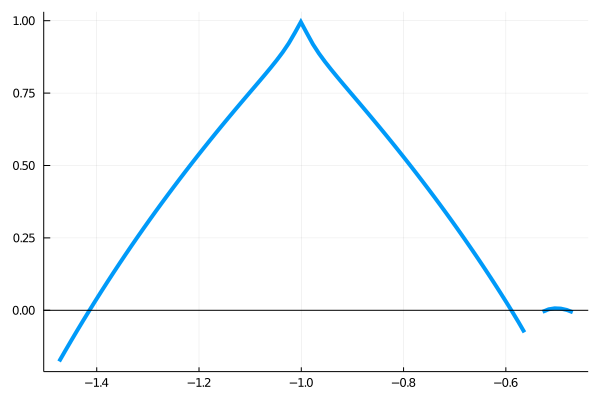

In [17]:
midi = cld(length(ys), 2)
p = plot(xs, solution.γ²[midi, :], linewidth=4, label="")
hline!(p, [0.0], color=:black, label="")

In [18]:
function fpoint(J̃, x₀)
    ftype = eltype(x₀)
    sol = nlsolve(
        (dx, x) -> network_f!(dx, x, J̃, zero(ftype)),
        (jac, x) -> network_jac!(jac, x, J̃, zero(ftype)),
        x₀;
        method=:newton,
        ftol=sqrt(eps(ftype)),
    )
    if !converged(sol)
        error("failed to converge")
    end
    return sol.zero
end

fpoint (generic function with 1 method)

In [19]:
x₀ = x̂
jac_ = similar(J̃)
σs = ftype(0.0):ftype(0.01):ftype(1.5)
evmaxs = fill(ftype(NaN), length(σs))
x₀s = fill(ftype(NaN), (length(x₀), length(σs)))
for (i, σ) in enumerate(σs)
    J̃ = Ĵ + σ * J
    x₀s[:, i] = x₀ = fpoint(J̃, x₀)
    network_jac!(jac_, x₀, J̃, zero(ftype))
    evmaxs[i] = maximum(real(eigvals(jac_)))
end

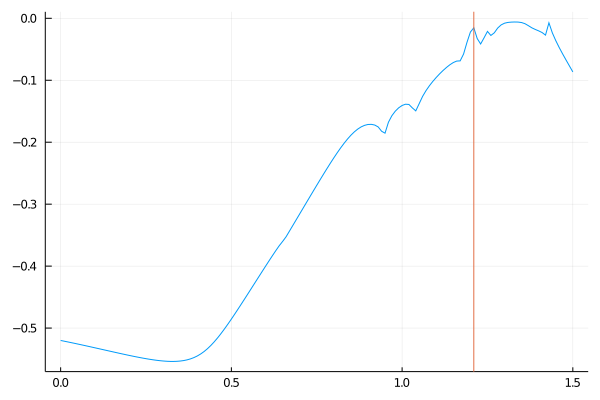

In [20]:
vl = [1.21]
plot(σs, evmaxs, label="")
vline!(vl, label="")

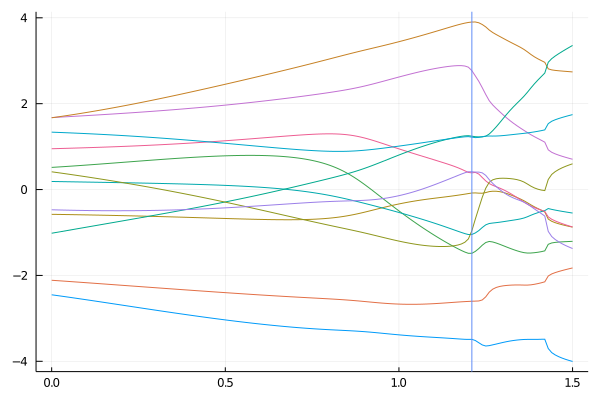

In [21]:
plot(σs, x₀s[1:12, :]', label="")
vline!(vl, label="")

In [22]:
println(repr("text/plain", [σs evmaxs]))

151×2 Array{Float64,2}:
 0.0   -0.519993
 0.01  -0.521105
 0.02  -0.522234
 0.03  -0.523381
 0.04  -0.524543
 0.05  -0.525721
 0.06  -0.526912
 0.07  -0.528116
 0.08  -0.52933
 0.09  -0.530554
 0.1   -0.531786
 0.11  -0.533023
 0.12  -0.534264
 0.13  -0.535507
 0.14  -0.53675
 0.15  -0.537989
 0.16  -0.539222
 0.17  -0.540445
 0.18  -0.541656
 0.19  -0.54285
 0.2   -0.544024
 0.21  -0.545171
 0.22  -0.546288
 0.23  -0.547367
 0.24  -0.548402
 0.25  -0.549384
 0.26  -0.550305
 0.27  -0.551153
 0.28  -0.551916
 0.29  -0.552579
 0.3   -0.553124
 0.31  -0.553531
 0.32  -0.553776
 0.33  -0.553828
 0.34  -0.553654
 0.35  -0.553212
 0.36  -0.552454
 0.37  -0.551324
 0.38  -0.549761
 0.39  -0.547698
 0.4   -0.54507
 0.41  -0.541816
 0.42  -0.537892
 0.43  -0.53328
 0.44  -0.52799
 0.45  -0.522063
 0.46  -0.515565
 0.47  -0.508573
 0.48  -0.501173
 0.49  -0.493442
 0.5   -0.485451
 0.51  -0.477258
 0.52  -0.468912
 0.53  -0.460453
 0.54  -0.451913
 0.55  -0.443318
 0.56  -0.43469
 0.57  -0.4260